In [11]:
import os
import requests
import cdsapi
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

## CHANGE DIRECTORYYYY
OUTPUT_DIR = "../../01_data/1.2_raw_api/era5_hourly_temp"
os.makedirs(OUTPUT_DIR, exist_ok=True)

GEO_DIR = "../../01_data/1.3_raw_other/mapping"
os.makedirs(GEO_DIR, exist_ok=True)

CLEANED_DIR = "../../01_data/2_cleaned/weather"
os.makedirs(CLEANED_DIR, exist_ok=True)

<Axes: >

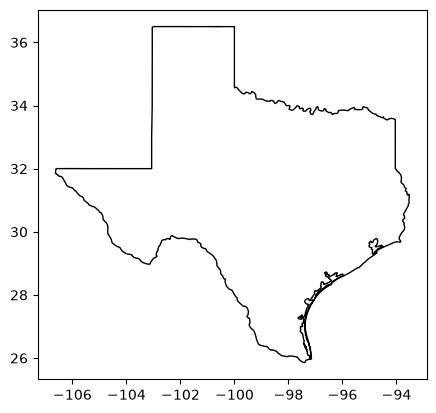

In [12]:
# Texas state boundary, for clipping the bbox download down to the actual state shape
TEXAS_GEOJSON_URL = "https://raw.githubusercontent.com/glynnbird/usstatesgeojson/master/texas.geojson"
texas_geojson_path = os.path.join(GEO_DIR, "texas_state_boundary.geojson")

if not os.path.exists(texas_geojson_path):
    resp = requests.get(TEXAS_GEOJSON_URL, timeout=30)
    resp.raise_for_status()
    with open(texas_geojson_path, "wb") as f:
        f.write(resp.content)

texas_gdf = gpd.read_file(texas_geojson_path).to_crs("EPSG:4326")
texas_boundary = texas_gdf.union_all()
texas_gdf.plot(edgecolor="black", facecolor="none")

In [13]:
# Texas geo box
# North, West, South, East
AREA = [37, -107, 25.5, -93]

In [14]:
from dotenv import load_dotenv

load_dotenv()
CDS_API_URL = os.environ["CDS_API_URL"]
CDS_API_KEY = os.environ["CDS_API_KEY"]  # https://cds.climate.copernicus.eu/profile
client = cdsapi.Client(url=CDS_API_URL, key=CDS_API_KEY)

In [15]:
# 1. Define the desired time range in Central Prevailing Time (CPT), convert to UTC
#    i.e. ERCOT local wall-clock time (America/Chicago, DST-observing).
CPT = "America/Chicago"
start_cpt = pd.Timestamp("2021-01-01 00:00", tz=CPT)
end_cpt   = pd.Timestamp("2021-01-31 23:00", tz=CPT)

start_utc = start_cpt.tz_convert("UTC")
end_utc = end_cpt.tz_convert("UTC")

print(f'{start_utc} -> {end_utc}')

# define tail end gap
# Jan + 5 hours in Feb


2021-01-01 06:00:00+00:00 -> 2021-02-01 05:00:00+00:00


In [16]:
# 2. Download: main month (full UTC calendar month) + boundary hours
#    Option A: two small requests instead of one bloated cartesian product.

def retrieve_if_missing(client, request, out_path):
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        print(f"Skipping (already exists): {out_path}")
        return
    client.retrieve("reanalysis-era5-single-levels", request, out_path)
    print(f"Saved: {out_path}")

# main request: full January in UTC
main_nc = os.path.join(OUTPUT_DIR, "era5_texas_t2m_hourly_test_main.nc")
retrieve_if_missing(client, {
    "product_type": ["reanalysis"],
    "variable": ["2m_temperature"],
    "year": [str(start_utc.year)],
    "month": [f"{start_utc.month:02d}"],
    "day": [f"{d:02d}" for d in range(1, 32)],
    "time": [f"{h:02d}:00" for h in range(24)],
    "area": AREA,
    "data_format": "netcdf",
    "download_format": "unarchived",
}, main_nc)

# boundary request: only the extra UTC hours that spill into the next month
# e.g. Feb 1 00:00–05:00 UTC for CPT Jan 31 18:00–23:00
boundary_nc = os.path.join(OUTPUT_DIR, "era5_texas_t2m_hourly_test_boundary.nc")
boundary_hours = [f"{h:02d}:00" for h in range(end_utc.hour + 1)]
retrieve_if_missing(client, {
    "product_type": ["reanalysis"],
    "variable": ["2m_temperature"],
    "year": [str(end_utc.year)],
    "month": [f"{end_utc.month:02d}"],
    "day": [f"{end_utc.day:02d}"],
    "time": boundary_hours,
    "area": AREA,
    "data_format": "netcdf",
    "download_format": "unarchived",
}, boundary_nc)

print(f"Main: {start_utc.month:02d}/{start_utc.year}, all days/hours")
print(f"Boundary: {end_utc.year}-{end_utc.month:02d}-{end_utc.day:02d}, hours {boundary_hours}")

Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_test_main.nc


2026-07-29 11:29:27,163 INFO Request ID is be8e71ba-3fc6-49d1-a83e-5c438d238543
2026-07-29 11:29:27,304 INFO status has been updated to accepted
2026-07-29 11:29:41,227 INFO status has been updated to successful


4f85be5cc1eb7bf9c9b52c3d0998c5b7.nc:   0%|          | 0.00/52.9k [00:00<?, ?B/s]

Saved: ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_test_boundary.nc
Main: 01/2021, all days/hours
Boundary: 2021-02-01, hours ['00:00', '01:00', '02:00', '03:00', '04:00', '05:00']


In [17]:
# 3. Mask to Texas boundary, average, convert UTC -> CPT (hour-ending)
def get_texas_mean(nc_paths, start_cpt=None, end_cpt=None):
    if isinstance(nc_paths, str):
        nc_paths = [nc_paths]

    ds = xr.concat([xr.open_dataset(p) for p in nc_paths], dim="valid_time")

    lon2d, lat2d = np.meshgrid(ds["longitude"].values, ds["latitude"].values)
    grid_points = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(lon2d.ravel(), lat2d.ravel()),
        crs="EPSG:4326",
    )
    in_texas = grid_points.within(texas_boundary).values.reshape(lat2d.shape)

    texas_mask = xr.DataArray(
        in_texas,
        dims=("latitude", "longitude"),
        coords={"latitude": ds["latitude"], "longitude": ds["longitude"]},
    )
    
    ds_texas = ds.where(texas_mask)

    t2m_hourly_mean = ds_texas["t2m"].mean(dim=["latitude", "longitude"])

    t2m_hourly_mean_df = t2m_hourly_mean.to_dataframe(name="t2m_mean_K").reset_index()
    t2m_hourly_mean_df["t2m_mean_F"] = (t2m_hourly_mean_df["t2m_mean_K"] - 273.15) * 9 / 5 + 32

    df = t2m_hourly_mean_df.filter(['valid_time', 't2m_mean_F'])

    # Convert UTC valid_time -> CPT, shift +1h to hour-ending to match ERCOT,
    # then drop tz for merge.
    valid_time_cpt = (
        pd.to_datetime(df['valid_time'], utc=True)
          .dt.tz_convert(CPT)
        + pd.Timedelta(hours=1)
    )
    df['valid_time'] = valid_time_cpt.dt.tz_localize(None)

    # Trim to exact CPT window (already hour-ending)
    if start_cpt is not None and end_cpt is not None:
        he_start = start_cpt + pd.Timedelta(hours=1)
        he_end   = end_cpt   + pd.Timedelta(hours=1)
        mask = (valid_time_cpt >= he_start) & (valid_time_cpt <= he_end)
        df = df[mask.values].reset_index(drop=True)

    # DST fall-back: two UTC hours collapse to the same naive CPT hour;
    # average them so the output has one unique row per local hour.
    df = df.groupby("valid_time", as_index=False)["t2m_mean_F"].mean()

    df = df.rename(columns={'valid_time': 'datetime', 't2m_mean_F': 'tx_temp'})
    return df

In [18]:
df = get_texas_mean([main_nc, boundary_nc], start_cpt=start_cpt, end_cpt=end_cpt)
df

,datetime,tx_temp
0,2021-01-01 01:00:00,35.301445
1,2021-01-01 02:00:00,34.923515
2,2021-01-01 03:00:00,34.651550
3,2021-01-01 04:00:00,33.962486
4,2021-01-01 05:00:00,32.179901
...,...,...
739,2021-01-31 20:00:00,56.472923
740,2021-01-31 21:00:00,53.850761
741,2021-01-31 22:00:00,47.788727
742,2021-01-31 23:00:00,47.092247


In [19]:
df.to_csv(os.path.join(CLEANED_DIR, f'Texas Hourly Temperature Average test.csv'), index=False)

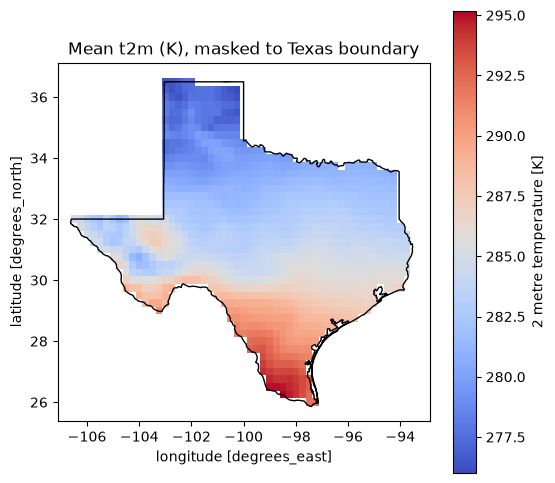

In [21]:
# sanity check: shaded region should trace the Texas outline, not the bbox rectangle
nc_path = os.path.join(OUTPUT_DIR, f"era5_texas_t2m_hourly_test_boundary.nc")
ds = xr.open_dataset(nc_path)

lon2d, lat2d = np.meshgrid(ds["longitude"].values, ds["latitude"].values)
grid_points = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(lon2d.ravel(), lat2d.ravel()),
        crs="EPSG:4326",
    )
in_texas = grid_points.within(texas_boundary).values.reshape(lat2d.shape)

texas_mask = xr.DataArray(
        in_texas,
        dims=("latitude", "longitude"),
        coords={"latitude": ds["latitude"], "longitude": ds["longitude"]},
    )
    
ds_texas = ds.where(texas_mask)

fig, ax = plt.subplots(figsize=(6, 6))
ds_texas["t2m"].mean("valid_time").plot(ax=ax, x="longitude", y="latitude", cmap="coolwarm")
texas_gdf.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Mean t2m (K), masked to Texas boundary")
plt.show()